# Simulated Annealing for the CVRPTW

## 1. Introduction

SA builds customer routes subject to capacity, time windows, depot return and fleet limits. The objective is total distance, without a vehicle-count penalty. Solomon and Homberger arcs are truncated to one decimal to match their reference costs.

Every full run now uses **solver seed 1, no wall-clock limit and 10 million proposed moves**. Temperature decreases according to move count. The 256-move construction demonstration is the only shorter search.

| Role | Instances | Seed | Runs |
| --- | --- | --- | --- |
| Temperature tuning | C101, C201, R101, R201, RC101, RC201 | 1 | 12 settings x 6 instances = 72 |
| Solomon test campaign | The other 50 instances | 1 | 50 |
| Homberger size study | R1_4_1, R1_8_1, R1_10_1 | 1 | 3 |
| Synthetic scaling example | 10,000 customers plus depot | 1 | 1 |

Temperature settings are selected only from the tuning instances. Single-seed results do not estimate variability between random seeds. Existing results from before this configuration are preserved in [SA_before_single_seed_2026-11-12.ipynb](archive/SA_before_single_seed_2026-11-12.ipynb). They belong to a different protocol and should not be pooled with these results.


## 2. Imports and configuration

Install the project with `pip install -e ".[dev]"`. NetworkX is also needed for section 11. Compilation is performed once on synthetic data outside the measured runs. Route construction, search and final validation are included in measured solver runtime.

`TIME_LIMIT=None` disables the deadline. `ITERATIONS=10_000_000` sets the finite cooling schedule, and tuning and test seeds both contain only 1. The reserved tuning and test instances remain disjoint. The notebook reports measured runtime rather than imposing a time budget. No quick-check mode is used.


In [1]:
import sys
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vrplib
from scipy import stats

ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'cvrp').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for folder in (ROOT / 'src', ROOT / 'experiments'):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
import solomon_study as study
from cvrp import Solution
from cvrp.sa import SAParams, SAResult, sa
from cvrp.sa_static import warmup
from cvrp.sa_protocol import (
    execute_jobs, tuning_jobs, benchmark_jobs, choose_parameters,
    validate_runs, summarize,
)
from cvrp.viz import plot_routes

pd.set_option('display.float_format', '{:.3f}'.format)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
CLASSES = ['C1', 'C2', 'R1', 'R2', 'RC1', 'RC2']
warmup()  # Synthetic compilation before timed runs.
print('Python:', sys.version.split()[0], '| Platform:', platform.platform())

Python: 3.14.7 | Platform: Windows-11-10.0.26300-SP0


In [2]:
WORKERS = study.WORKERS
TIME_LIMIT = None
ITERATIONS = 10_000_000
TUNING = tuple(study.TUNING)
TUNE_SEEDS = (1,)
TEST_SEEDS = (1,)
GRID = study.ALGORITHMS['sa'][1]
print(f'No time limit | {ITERATIONS:,} proposed moves/run | Workers: {WORKERS}')
print('Tuning seeds:', TUNE_SEEDS, '| Test seeds:', TEST_SEEDS, '| Grid:', GRID)


No time limit | 10,000,000 proposed moves/run | Workers: 7
Tuning seeds: (1,) | Test seeds: (1,) | Grid: {'initial_temperature_factor': [0.0025, 0.005, 0.01], 'final_temperature': [0.005, 0.01, 0.02, 0.05]}


## 3. Dataset loading and reference checks

The repository loader reads the supplied local .txt instances and distance-oriented .sol references, truncates Euclidean arcs to one decimal and retains the shared fleet constraints. Reference routes must be feasible and reproduce their stored cost.

All 56 files are checked: six tuning instances and fifty separate test instances. Reference routes are used for gap calculation, never as starting solutions or move-selection information.


In [3]:
names = sorted(p.stem for p in study.DATA.glob('*.txt'))
assert len(names) == 56 and set(TUNING).issubset(names)
TEST_NAMES = tuple(n for n in names if n not in TUNING)
assert len(TEST_NAMES) == 50
rows = []
for name in names:
    inst = study.load(name)
    reference = Solution([list(r) for r in vrplib.read_solution(study.DATA / f'{name}.sol')['routes']])
    assert reference.is_feasible(inst), (name, reference.violations(inst))
    assert np.isclose(reference.cost(inst), inst.best_known, rtol=0, atol=1e-6)
    rows.append(dict(instance=name, family=name[:-2],
                     split='tuning' if name in TUNING else 'test',
                     best_known=inst.best_known, reference_routes=len(reference)))
instances = pd.DataFrame(rows)
print('All 56 references are feasible and reproduce their costs.')
display(instances.groupby(['family', 'split']).size().unstack(fill_value=0).reindex(CLASSES))

All 56 references are feasible and reproduce their costs.


split,test,tuning
family,,
C1,8,1
C2,7,1
R1,11,1
R2,10,1
RC1,7,1
RC2,7,1


## 4. SA implementation

The public solver follows the repository parameter/result conventions:

```python
result = sa(inst, SAParams(time_limit=None, iterations=10_000_000), seed=1)
result.best        # shared Solution
result.cost        # shared distance evaluation
result.runtime     # elapsed seconds
result.iterations  # proposed SA move attempts
result.history     # best-improvement batch snapshots
```

`sa.py` contains the parameter/result classes and public solver. `sa_vrptw.py` contains construction and the independent route evaluator; `sa_static.py` contains the compiled static moves. The solver reads `inst.dist` without changing its rounding or modifying the input instance.

```
construct a randomized feasible initial solution
current = best = initial
until the proposed-move schedule is complete:
    propose relocate, swap, reversal, short-chain move or route-tail exchange
    reject candidates that break capacity or time windows
    accept improvements, or worsening moves with probability exp(-delta / T)
    update best and cool according to proposed move count
validate best with the shared Solution evaluator
```

Temperature follows `T(k)=T0*(Tf/T0)**(k/N)`, where N is the proposed-move budget, with `T0=max(1, factor*initial_distance)`. Defaults are heuristic; the tuning section selects `factor` and `Tf` using only the reserved six instances. SA records history at improving batches rather than storing millions of rows. One history snapshot is not one move.

### 4.1 Construction and search on C101

Construction: 2440.1; after 256 move attempts: 2352.9


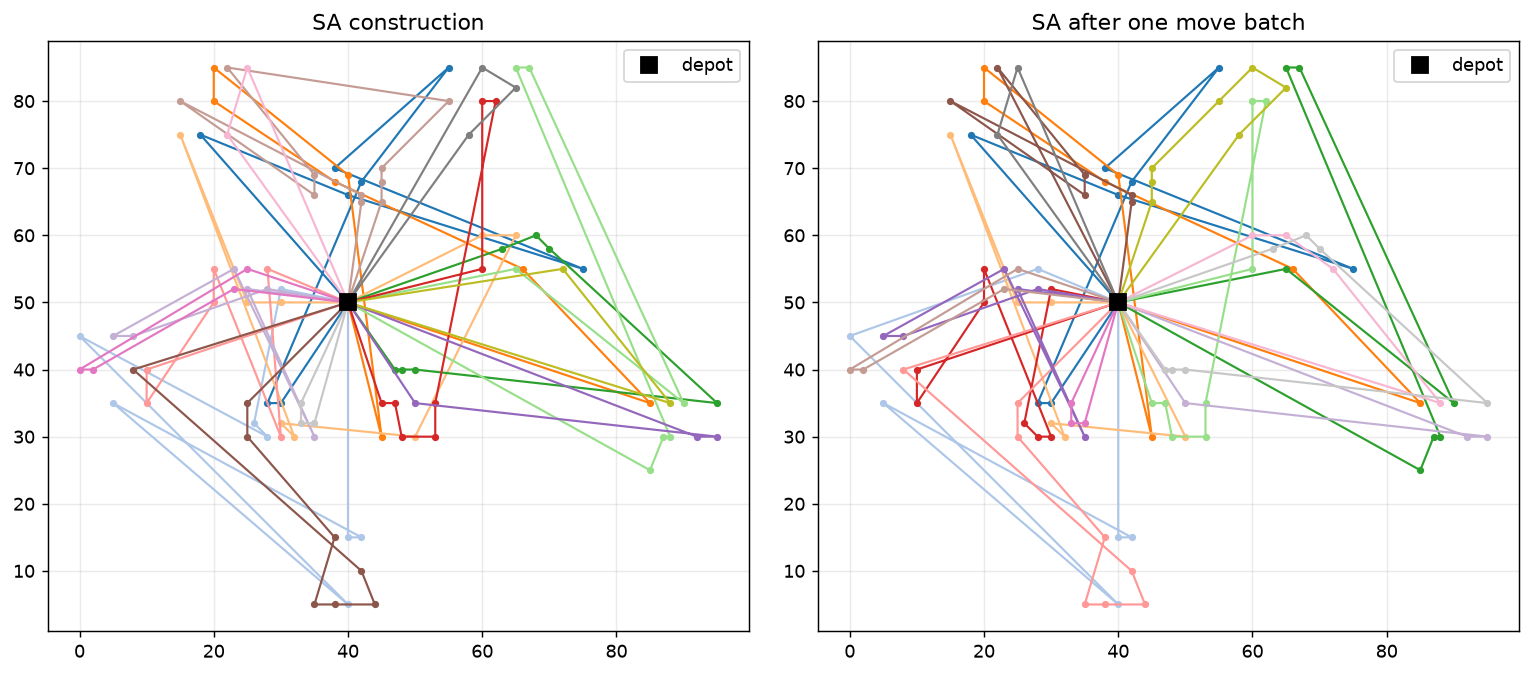

In [4]:
inst = study.load('C101')
demo = sa(inst, SAParams(iterations=256, time_limit=TIME_LIMIT), seed=1)
assert demo.best is not None and demo.best.is_feasible(inst)
print(f'Construction: {demo.initial.cost(inst):.1f}; after 256 move attempts: {demo.cost:.1f}')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_routes(inst, demo.initial, ax=axes[0], title='SA construction')
plot_routes(inst, demo.best, ax=axes[1], title='SA after one move batch')
plt.tight_layout(); plt.show()

## 5. Single-instance testing

Use the same distance evaluator, seed 1 and 10-million-move schedule as the campaign. No wall-clock deadline applies. The solver reports its measured runtime and best-improvement history. With the same data, parameters and seed, the move-count schedule is independent of machine speed.


RC101: distance 1656.8, reference 1619.8, gap 2.284%
10,000,000 proposed moves in 2.300 s; 18 routes; stop: iterations


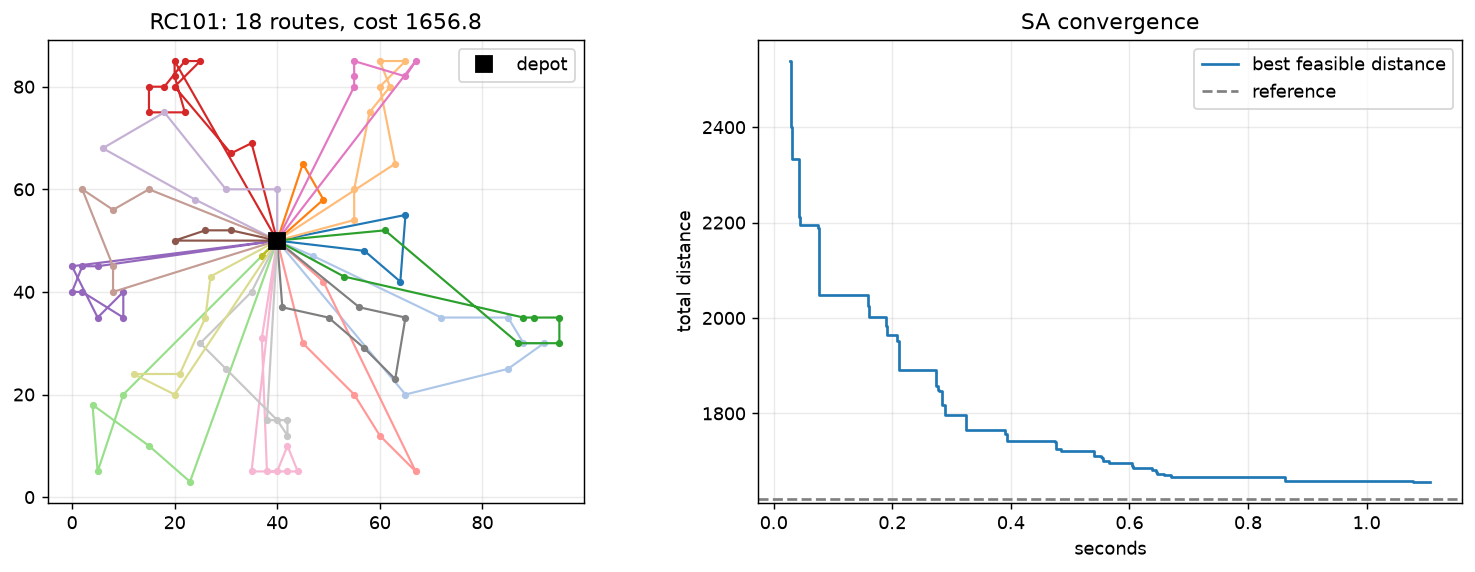

In [5]:
INSTANCE = 'RC101'
SEED = TEST_SEEDS[0]
inst = study.load(INSTANCE)
single = sa(inst, SAParams(time_limit=TIME_LIMIT, iterations=ITERATIONS), seed=SEED)
assert single.best is not None and single.best.violations(inst) == []
print(f'{INSTANCE}: distance {single.cost:.1f}, reference {inst.best_known:.1f}, '
      f'gap {100*(single.cost/inst.best_known-1):.3f}%')
print(f'{single.iterations:,} proposed moves in {single.runtime:.3f} s; '
      f'{len(single.best)} routes; stop: {single.stop_reason}')
h = pd.DataFrame(single.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_routes(inst, single.best, ax=axes[0])
axes[1].step(h.seconds, h.best, where='post', label='best feasible distance')
axes[1].axhline(inst.best_known, ls='--', color='gray', label='reference')
axes[1].set(xlabel='seconds', ylabel='total distance', title='SA convergence')
axes[1].legend(); plt.tight_layout(); plt.show()

## 6. Parameter tuning on six instances

Initial-temperature factors 0.0025, 0.005 and 0.01 are crossed with final temperatures 0.005, 0.01, 0.02 and 0.05. Twelve settings run on six reserved instances with seed 1, no time limit and 10 million proposed moves each: 72 tuning runs.

The setting with the lowest mean tuning gap is selected. None of the fifty test instances participates in selection. The selected values are candidates evaluated on this fixed tuning set, not proven optimal parameters.


72 SA tuning runs


,params,mean_gap
0,"{'initial_temperature_factor': 0.0025, 'final_...",0.679
1,"{'initial_temperature_factor': 0.005, 'final_t...",0.712
2,"{'initial_temperature_factor': 0.0025, 'final_...",0.780
3,"{'initial_temperature_factor': 0.0025, 'final_...",0.860
4,"{'initial_temperature_factor': 0.01, 'final_te...",0.885
5,"{'initial_temperature_factor': 0.005, 'final_t...",1.037
6,"{'initial_temperature_factor': 0.01, 'final_te...",1.045
7,"{'initial_temperature_factor': 0.005, 'final_t...",1.100
8,"{'initial_temperature_factor': 0.0025, 'final_...",1.128
9,"{'initial_temperature_factor': 0.01, 'final_te...",1.232


Selected parameters: {'initial_temperature_factor': 0.0025, 'final_temperature': 0.005}


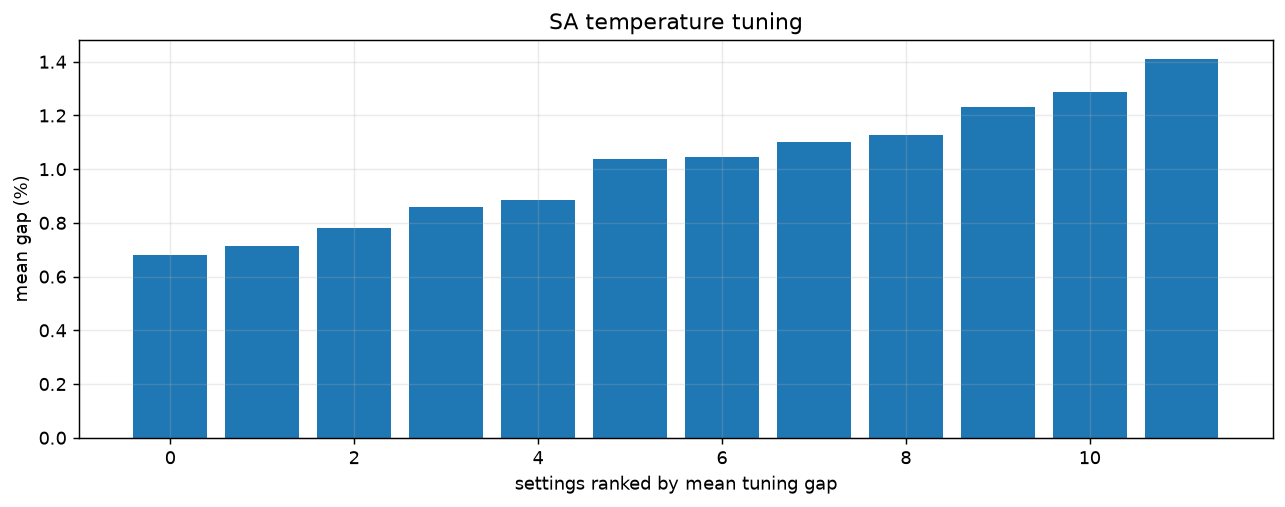

In [6]:
jobs = tuning_jobs(study, seeds=TUNE_SEEDS, time_limit=TIME_LIMIT, iterations=ITERATIONS)
print(f'{len(jobs)} SA tuning runs')
tuning = execute_jobs(jobs, study.run_one, WORKERS)
CHOSEN, tuning_ranking = choose_parameters(tuning)
assert set(tuning.instance) == set(TUNING)
assert set(tuning.seed) == set(TUNE_SEEDS)
display(tuning_ranking)
print('Selected parameters:', CHOSEN)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(tuning_ranking)), tuning_ranking.mean_gap)
ax.set(xlabel='settings ranked by mean tuning gap', ylabel='mean gap (%)', title='SA temperature tuning')
ax.ticklabel_format(axis='y', style='plain', useOffset=False)
plt.tight_layout(); plt.show()

## 7. Test campaign: fifty instances, one seed, no time limit

Run the selected temperature settings on the fifty instances excluded from tuning, with seed 1 and 10 million proposed moves each. SA builds its own initial solution, independently of the reference routes.

Validation checks feasibility, reference-gap consistency, complete instance/seed coverage, explicitly disabled deadlines and completion of the requested iteration budget. A single seed provides no within-instance estimate of random-seed variability.


In [7]:
jobs = benchmark_jobs(study, CHOSEN, names=TEST_NAMES, seeds=TEST_SEEDS,
                      time_limit=TIME_LIMIT, iterations=ITERATIONS)
print(f'{len(jobs)} SA test runs')
bench = execute_jobs(jobs, study.run_one, WORKERS)
validate_runs(bench, TEST_NAMES, TEST_SEEDS, time_limit=TIME_LIMIT, iterations=ITERATIONS)
bench['class'] = bench.instance.str[:-2]
per_inst = summarize(bench)
print(f'{len(bench)} runs, {bench.instance.nunique()} instances; all feasible.')
print(f'Elapsed time: {bench.seconds.min():.2f} to {bench.seconds.max():.2f} s')
with pd.option_context('display.max_rows', None):
    display(per_inst.round(3))
    display(bench[['instance', 'seed', 'cost', 'gap', 'routes', 'seconds', 'iterations']])

50 SA test runs
50 runs, 50 instances; all feasible.
Elapsed time: 2.78 to 5.12 s


,instance,BKS,best,mean,distance_std,gap_best,gap_mean,gap_std,routes,seconds,seconds_std,iterations,iterations_std
0,C102,827.300,834.100,834.100,NaN,0.822,0.822,NaN,10.000,2.840,NaN,10000000.000,NaN
1,C103,826.300,843.000,843.000,NaN,2.021,2.021,NaN,10.000,3.460,NaN,10000000.000,NaN
2,C104,822.900,835.700,835.700,NaN,1.555,1.555,NaN,10.000,3.030,NaN,10000000.000,NaN
3,C105,827.300,827.300,827.300,NaN,0.000,0.000,NaN,10.000,3.990,NaN,10000000.000,NaN
4,C106,827.300,827.300,827.300,NaN,0.000,0.000,NaN,10.000,3.250,NaN,10000000.000,NaN
5,C107,827.300,827.300,827.300,NaN,0.000,0.000,NaN,10.000,3.410,NaN,10000000.000,NaN
6,C108,827.300,827.300,827.300,NaN,0.000,0.000,NaN,10.000,3.450,NaN,10000000.000,NaN
7,C109,827.300,827.300,827.300,NaN,0.000,0.000,NaN,10.000,2.980,NaN,10000000.000,NaN
8,C202,589.100,589.100,589.100,NaN,-0.000,0.000,NaN,3.000,4.770,NaN,10000000.000,NaN
9,C203,588.700,597.800,597.800,NaN,1.546,1.546,NaN,3.000,4.490,NaN,10000000.000,NaN


,instance,seed,cost,gap,routes,seconds,iterations
0,C102,1,834.100,0.822,10,2.840,10000000
1,C103,1,843.000,2.021,10,3.460,10000000
2,C104,1,835.700,1.555,10,3.030,10000000
3,C105,1,827.300,0.000,10,3.990,10000000
4,C106,1,827.300,0.000,10,3.250,10000000
5,C107,1,827.300,0.000,10,3.410,10000000
6,C108,1,827.300,0.000,10,3.450,10000000
7,C109,1,827.300,0.000,10,2.980,10000000
8,C202,1,589.100,-0.000,3,4.770,10000000
9,C203,1,597.800,1.546,3,4.490,10000000


## 8. Results and visualization

Each test instance has one seed-1 observation. Family means describe variation across instances; no sample standard deviation across seeds is available. The per-instance plot therefore shows gap values without error bars. Undefined seed-standard-deviation fields remain NaN in the table.

Iterations count proposed moves, including infeasible and rejected proposals. Every full run completes the same move budget, while measured runtime varies with instance difficulty and construction effort. There is no runtime deadline line in the histogram.


,instances,mean_gap,worst_gap,mean_seconds,mean_iterations
class,,,,,
C1,8,0.550,2.021,3.301,10000000.000
C2,7,0.775,3.843,4.630,10000000.000
R1,11,2.688,5.768,3.419,10000000.000
R2,10,3.674,5.617,3.921,10000000.000
RC1,7,3.927,6.498,3.267,10000000.000
RC2,7,2.860,5.154,3.594,10000000.000


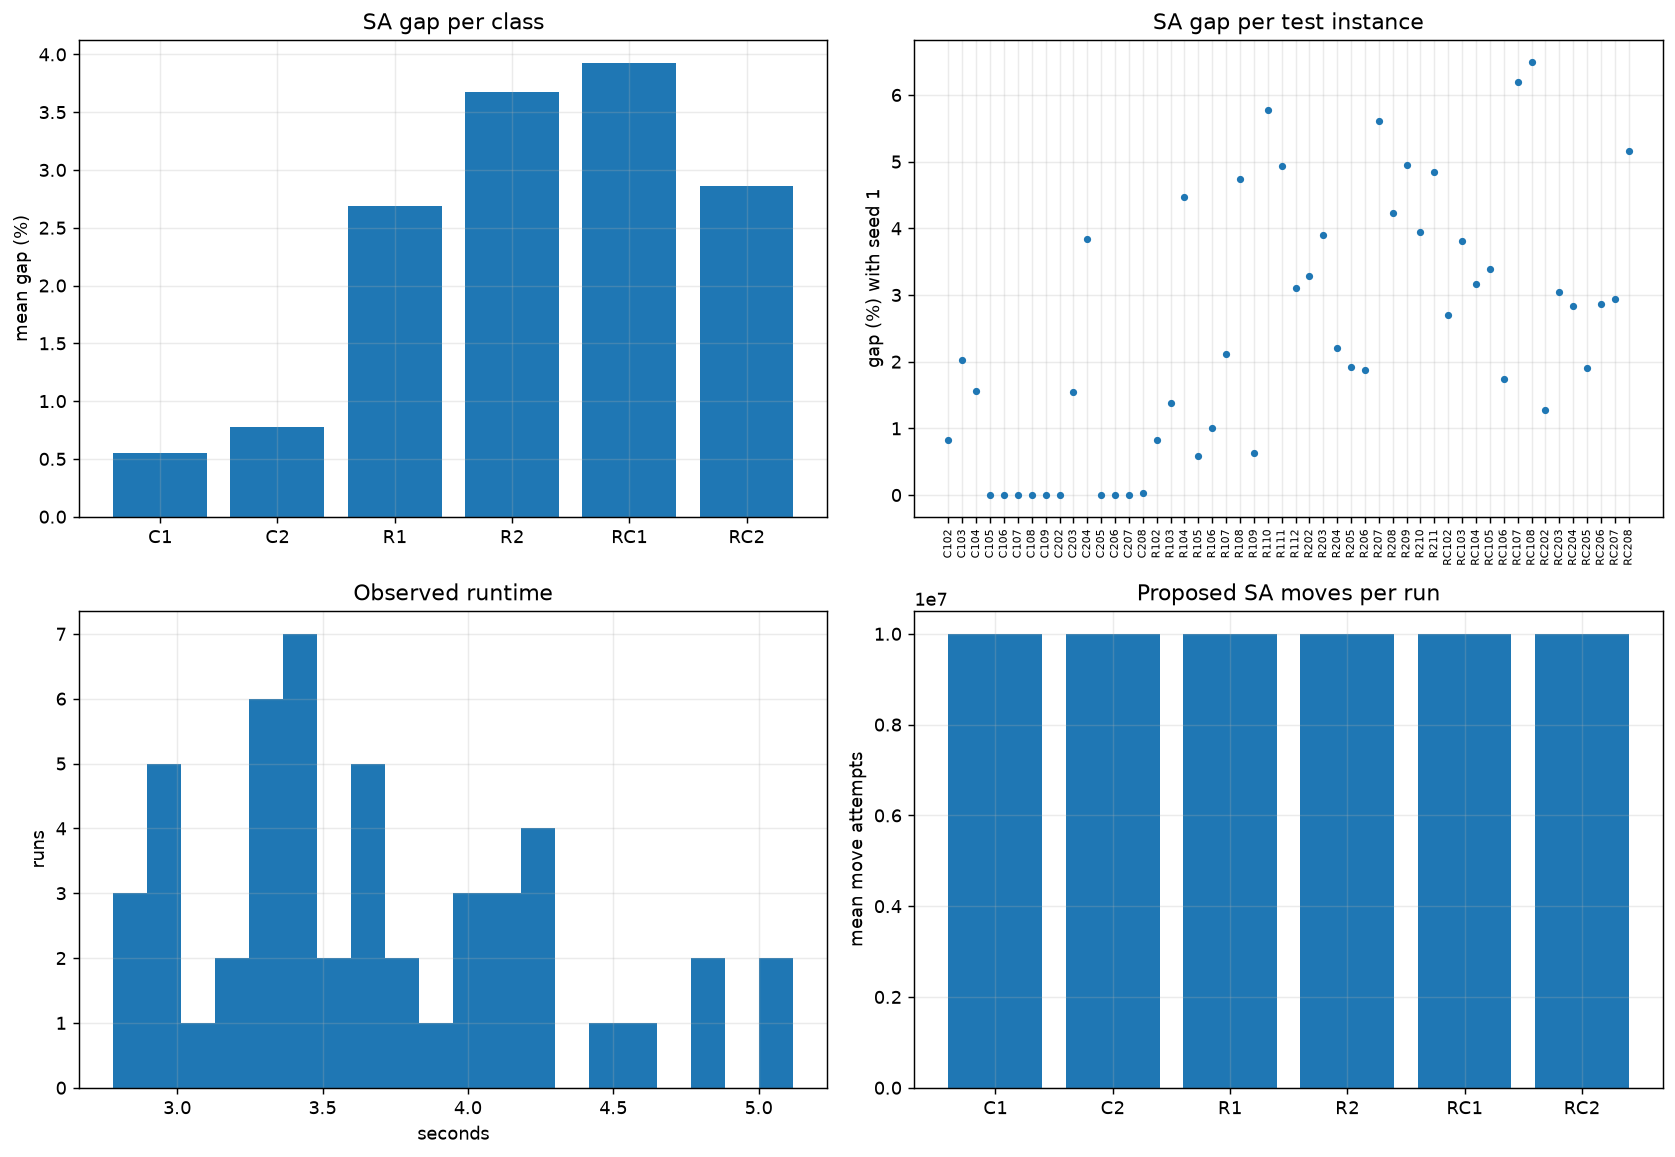

One seed per instance: between-seed standard deviations are unavailable.


In [8]:
cls = bench.groupby('class').agg(
    instances=('instance', 'nunique'), mean_gap=('gap', 'mean'), worst_gap=('gap', 'max'),
    mean_seconds=('seconds', 'mean'), mean_iterations=('iterations', 'mean'),
).reindex(CLASSES)
display(cls)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].bar(CLASSES, cls.mean_gap)
axes[0, 0].set(title='SA gap per class', ylabel='mean gap (%)')
order = per_inst.sort_values('instance').reset_index(drop=True)
axes[0, 1].plot(order.index, order.gap_mean, 'o', ms=3)
axes[0, 1].set(title='SA gap per test instance', ylabel='gap (%) with seed 1')
axes[0, 1].set_xticks(order.index, order.instance, rotation=90, fontsize=6)
axes[1, 0].hist(bench.seconds, bins=20)
axes[1, 0].set(title='Observed runtime', xlabel='seconds', ylabel='runs')
axes[1, 1].bar(CLASSES, cls.mean_iterations)
axes[1, 1].set(title='Proposed SA moves per run', ylabel='mean move attempts')
for ax in axes[0]:
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
plt.tight_layout(); plt.show()
print('One seed per instance: between-seed standard deviations are unavailable.')


## 9. Statistical analysis of SA

The statistical unit is the instance. The table summarizes seed-1 gaps within each Solomon class and a Student-t interval across instances. This interval describes variation among the fixed test instances, not random-seed uncertainty or guaranteed performance on unseen instances. No algorithm comparison is performed.


In [9]:
def ci95(values):
    values = np.asarray(values, dtype=float)
    return stats.t.ppf(0.975, len(values)-1) * values.std(ddof=1) / np.sqrt(len(values))

inst_means = bench.groupby(['class', 'instance']).gap.mean().reset_index()
table9 = inst_means.groupby('class').gap.agg(instances='size', mean='mean', ci95=ci95).reindex(CLASSES)
display(table9)

,instances,mean,ci95
class,,,
C1,8,0.550,0.689
C2,7,0.775,1.359
R1,11,2.688,1.327
R2,10,3.674,0.950
RC1,7,3.927,1.643
RC2,7,2.860,1.114


## 10. Conclusions and limitations

Conclusions use the newly executed one-seed, move-budget tables. They do not measure between-seed variability and are not directly interchangeable with the archived timed campaign.

The Solomon test instances contain 100 customers. The following Homberger and synthetic sections examine larger instances under the same move budget. These cases do not establish general scaling behavior or time-dependent traffic performance. Earlier exploratory development examined some test cases; keeping the reserved tuning set explicit does not erase that history.


In [10]:
print(f'Tuning: {len(tuning)} runs, chosen {CHOSEN}')
print(f'Test: {len(bench)} runs across {bench.instance.nunique()} instances; '
      f'mean gap {bench.gap.mean():.3f}%, all feasible {bench.feasible.all()}')
print('Seed 1 only; between-seed standard deviation is unavailable.')
print(f'Mean runtime: {bench.seconds.mean():.3f} s; mean proposed moves: {bench.iterations.mean():,.0f}')


Tuning: 72 runs, chosen {'initial_temperature_factor': 0.0025, 'final_temperature': 0.005}
Test: 50 runs across 50 instances; mean gap 2.473%, all feasible True
Seed 1 only; between-seed standard deviation is unavailable.
Mean runtime: 3.673 s; mean proposed moves: 10,000,000


## 10.1. Homberger gap study: 400, 800 and 1,000 customers

Use one R1 instance per size: `R1_4_1`, `R1_8_1` and `R1_10_1`. Each runs with **seed 1**, **no time limit** and **10 million proposed moves**: three runs in total. The shared SA solver uses the temperature settings selected by the earlier Solomon tuning, with no additional tuning on Homberger and no reference routes used as a starting solution.

Instances and matching references are in `data/homberger/`, downloaded from [PyVRP/Instances](https://github.com/PyVRP/Instances/tree/7474b068a8effa7f39448b241314b615c9271525/VRPTW). `sources.json` records exact URLs, revision and hashes. As specified by the [source conventions](https://github.com/PyVRP/Instances/blob/7474b068a8effa7f39448b241314b615c9271525/VRPTW/README.md), distances and travel times are truncated to one decimal, and the depot has zero service time. Each reference is independently checked for coverage, constraints and matching distance before reporting gaps. Files use VRPLIB format; customer counts exclude the depot.

Gap (%) = 100 * (SA distance / reference distance - 1). References are best-known values, not proven optima. Compilation is outside the timer; reported runtime includes initialization, search and final validation; stopping is by move count. This is a small size comparison within the R1 family. Earlier results are preserved in the archived notebook linked in the introduction.


In [11]:
import os
import homberger_study as homberger

HOMBERGER_NAMES = tuple(homberger.names())
HOMBERGER_SEEDS = TEST_SEEDS
HOMBERGER_TIME_LIMIT = TIME_LIMIT
HOMBERGER_PARAMS = dict(CHOSEN, iterations=ITERATIONS)
HOMBERGER_WORKERS = min(3, max(1, (os.cpu_count() or 2) - 1))
homberger_references = pd.DataFrame([homberger.check_reference(name) for name in HOMBERGER_NAMES])
assert homberger_references.n.tolist() == [400, 800, 1000]
print('Parameters from Solomon tuning:', HOMBERGER_PARAMS)
print(f'{len(HOMBERGER_NAMES)} instances x {len(HOMBERGER_SEEDS)} seeds; '
      f'no time limit; {ITERATIONS:,} moves/run; {HOMBERGER_WORKERS} workers')
display(homberger_references)


Parameters from Solomon tuning: {'initial_temperature_factor': 0.0025, 'final_temperature': 0.005, 'iterations': 10000000}
3 instances x 1 seeds; no time limit; 10,000,000 moves/run; 3 workers


,instance,n,best_known,reference_cost,reference_routes,reference_feasible
0,R1_4_1,400,10305.800,10305.800,41,True
1,R1_8_1,800,36345.000,36345.000,80,True
2,R1_10_1,1000,53026.100,53026.100,95,True


In [12]:
homberger_jobs = [(name, seed, dict(HOMBERGER_PARAMS), HOMBERGER_TIME_LIMIT)
                  for name in HOMBERGER_NAMES for seed in HOMBERGER_SEEDS]
homberger_runs = execute_jobs(homberger_jobs, homberger.run_one, HOMBERGER_WORKERS)
assert len(homberger_runs) == len(HOMBERGER_NAMES) * len(HOMBERGER_SEEDS)
assert not homberger_runs.duplicated(['instance', 'seed']).any()
assert set(zip(homberger_runs.instance, homberger_runs.seed)) == {
    (name, seed) for name in HOMBERGER_NAMES for seed in HOMBERGER_SEEDS}
assert homberger_runs.time_limit.isna().all()
assert homberger_runs.iterations.eq(ITERATIONS).all()
assert homberger_runs.stop_reason.eq('iterations').all()
print(f'Completed {len(homberger_runs)} runs; feasible: '
      f'{int(homberger_runs.feasible.sum())}/{len(homberger_runs)}')
display(homberger_runs.sort_values(['n', 'seed']).reset_index(drop=True))


Completed 3 runs; feasible: 3/3


,instance,n,algorithm,seed,params,time_limit,best_known,cost,gap,feasible,seconds,iterations,routes,stop_reason,error
0,R1_4_1,400,sa,1,"{'initial_temperature_factor': 0.0025, 'final_...",None,10305.800,11206.600,8.741,True,4.826,10000000,52,iterations,
1,R1_8_1,800,sa,1,"{'initial_temperature_factor': 0.0025, 'final_...",None,36345.000,43711.500,20.268,True,5.287,10000000,102,iterations,
2,R1_10_1,1000,sa,1,"{'initial_temperature_factor': 0.0025, 'final_...",None,53026.100,65245.200,23.044,True,4.915,10000000,120,iterations,


### Homberger results and comparison

There is one run per instance. Distances and gaps describe seed 1 only, and sample standard deviations across seeds are undefined. Plots omit error bars rather than treating missing variability as zero. All runs, including any failures, remain visible. This study covers only one R1 instance at each size.


,n,instance,reference,runs,successful_runs,feasible_rate,best_distance,mean_distance,distance_std,best_gap_pct,mean_gap_pct,gap_std_pct,mean_seconds,mean_iterations,mean_routes
0,400,R1_4_1,10305.800,1,1,1.000,11206.600,11206.600,NaN,8.741,8.741,NaN,4.826,10000000.000,52.000
1,800,R1_8_1,36345.000,1,1,1.000,43711.500,43711.500,NaN,20.268,20.268,NaN,5.287,10000000.000,102.000
2,1000,R1_10_1,53026.100,1,1,1.000,65245.200,65245.200,NaN,23.044,23.044,NaN,4.915,10000000.000,120.000


,instances,mean_gap,worst_gap,mean_seconds,mean_iterations
n,,,,,
400,1,8.741,8.741,4.826,10000000.000
800,1,20.268,20.268,5.287,10000000.000
1000,1,23.044,23.044,4.915,10000000.000


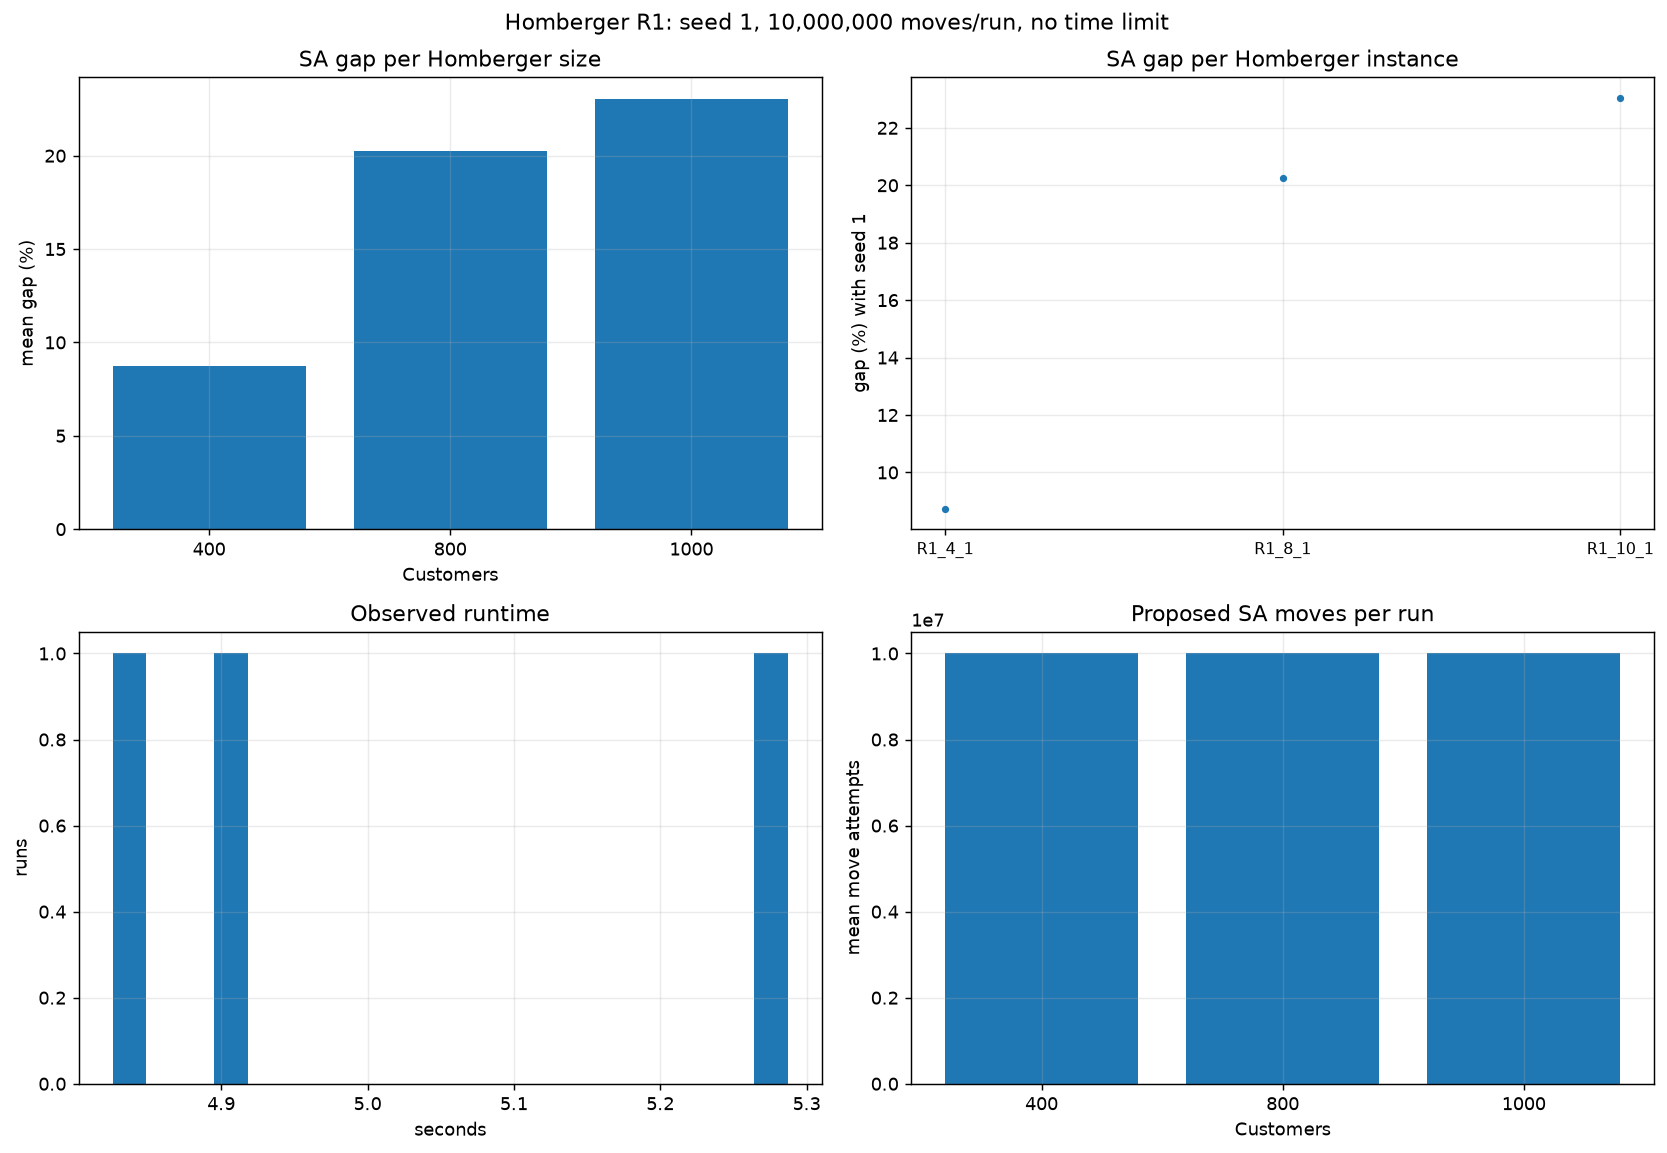

One seed per instance: seed standard deviations are unavailable.


In [13]:
homberger_summary = homberger_runs.groupby(['n', 'instance'], as_index=False).agg(
    reference=('best_known', 'first'), runs=('seed', 'size'),
    successful_runs=('feasible', 'sum'), feasible_rate=('feasible', 'mean'),
    best_distance=('cost', 'min'), mean_distance=('cost', 'mean'),
    distance_std=('cost', 'std'), best_gap_pct=('gap', 'min'),
    mean_gap_pct=('gap', 'mean'), gap_std_pct=('gap', 'std'),
    mean_seconds=('seconds', 'mean'), mean_iterations=('iterations', 'mean'),
    mean_routes=('routes', 'mean'))
display(homberger_summary)
homberger_size_summary = homberger_runs.groupby('n').agg(
    instances=('instance', 'nunique'), mean_gap=('gap', 'mean'), worst_gap=('gap', 'max'),
    mean_seconds=('seconds', 'mean'), mean_iterations=('iterations', 'mean'))
display(homberger_size_summary)

# Same four diagnostics as the Solomon results section, grouped by size instead of class.
homberger_fig, homberger_axes = plt.subplots(2, 2, figsize=(13, 9))
homberger_labels = homberger_size_summary.index.astype(str)
homberger_axes[0, 0].bar(homberger_labels, homberger_size_summary.mean_gap)
homberger_axes[0, 0].set(title='SA gap per Homberger size', xlabel='Customers', ylabel='mean gap (%)')
homberger_order = homberger_summary.sort_values('n').reset_index(drop=True)
homberger_axes[0, 1].plot(homberger_order.index, homberger_order.mean_gap_pct, 'o', ms=3)
homberger_axes[0, 1].set(title='SA gap per Homberger instance',
                          ylabel='gap (%) with seed 1')
homberger_axes[0, 1].set_xticks(homberger_order.index, homberger_order.instance, fontsize=9)
homberger_axes[1, 0].hist(homberger_runs.seconds, bins=20)
homberger_axes[1, 0].set(title='Observed runtime', xlabel='seconds', ylabel='runs')
homberger_axes[1, 1].bar(homberger_labels, homberger_size_summary.mean_iterations)
homberger_axes[1, 1].set(title='Proposed SA moves per run', xlabel='Customers',
                          ylabel='mean move attempts')
for homberger_ax in homberger_axes[0]:
    homberger_ax.ticklabel_format(axis='y', style='plain', useOffset=False)
homberger_fig.suptitle(f'Homberger R1: seed 1, {ITERATIONS:,} moves/run, no time limit')
homberger_fig.tight_layout()
plt.show()
print('One seed per instance: seed standard deviations are unavailable.')
if not homberger_runs.feasible.all():
    print('Failed runs retained; their gaps are undefined:')
    display(homberger_runs.loc[~homberger_runs.feasible, ['instance', 'seed', 'stop_reason', 'error']])


## 11. SA on a single 10,000-customer NetworkX graph

This section uses one reproducible uniform geometric graph: 10,000 customers plus depot node 0, capacity 100, graph seed 101 and solver seed 1. NetworkX generates the spatial graph. Its sparse proximity edges describe the layout; routing uses complete Euclidean distances computed from the node positions, rather than shortest paths along proximity edges. The distance matrix alone occupies about 0.80 GB in float64.

There is no quick check or multi-size campaign. Only SA runs on this instance. A feasible sweep solution initializes the shared solver. Synthetic data have no known optimum, so improvement is measured against that initial solution, not an optimality gap. The earlier benchmark cells and saved results remain unchanged.


In [14]:
import networkx as nx
from scipy.spatial.distance import cdist
from cvrp.instance import Instance

def synthetic_instance(n, layout, capacity, graph_seed):
    """Generate NetworkX positions; avoid Python objects for all O(n^2) edges."""
    rng = np.random.default_rng(graph_seed)
    if layout == 'uniform':
        customers = rng.uniform(0, 100, (n, 2))
    elif layout == 'clustered':
        centers = rng.uniform(10, 90, (8, 2))
        customers = np.clip(centers[rng.integers(0, 8, n)]
                            + rng.normal(0, 4, (n, 2)), 0, 100)
    else:
        raise ValueError(f'Unknown layout: {layout}')
    coords = np.vstack(([50.0, 50.0], customers))
    positions = {i: tuple(xy) for i, xy in enumerate(coords)}
    graph = nx.random_geometric_graph(n + 1, radius=3.0, pos=positions,
                                     seed=graph_seed)
    demands = np.r_[0.0, rng.integers(1, 11, n).astype(float)]
    nx.set_node_attributes(graph, dict(enumerate(demands)), 'demand')
    # cdist allocates one dense matrix, avoiding a large (n,n,2) temporary.
    distance = cdist(np.array([graph.nodes[i]['pos'] for i in range(n + 1)]), coords)
    instance = Instance(name=f'nx-{layout}-n{n}-q{capacity:g}-g{graph_seed}',
                        coords=coords, demands=demands, capacity=capacity, dist=distance)
    return graph, instance


def synthetic_sweep(instance):
    """O(n log n) capacity-feasible common start, independent of reference results."""
    xy = instance.coords[1:] - instance.coords[0]
    order = np.argsort(np.arctan2(xy[:, 1], xy[:, 0])) + 1
    routes, route, load = [], [], 0.0
    for node in order:
        if route and load + instance.demands[node] > instance.capacity:
            routes.append(route)
            route, load = [], 0.0
        route.append(int(node))
        load += instance.demands[node]
    if route:
        routes.append(route)
    return Solution(routes)


### Initial customer and depot layout

All 10,000 customers are shown in blue, with depot node 0 marked by a red star at (50, 50). This is the input layout before constructing or optimizing routes. Proximity edges are omitted for clarity; the SA cost matrix still uses complete Euclidean distances.


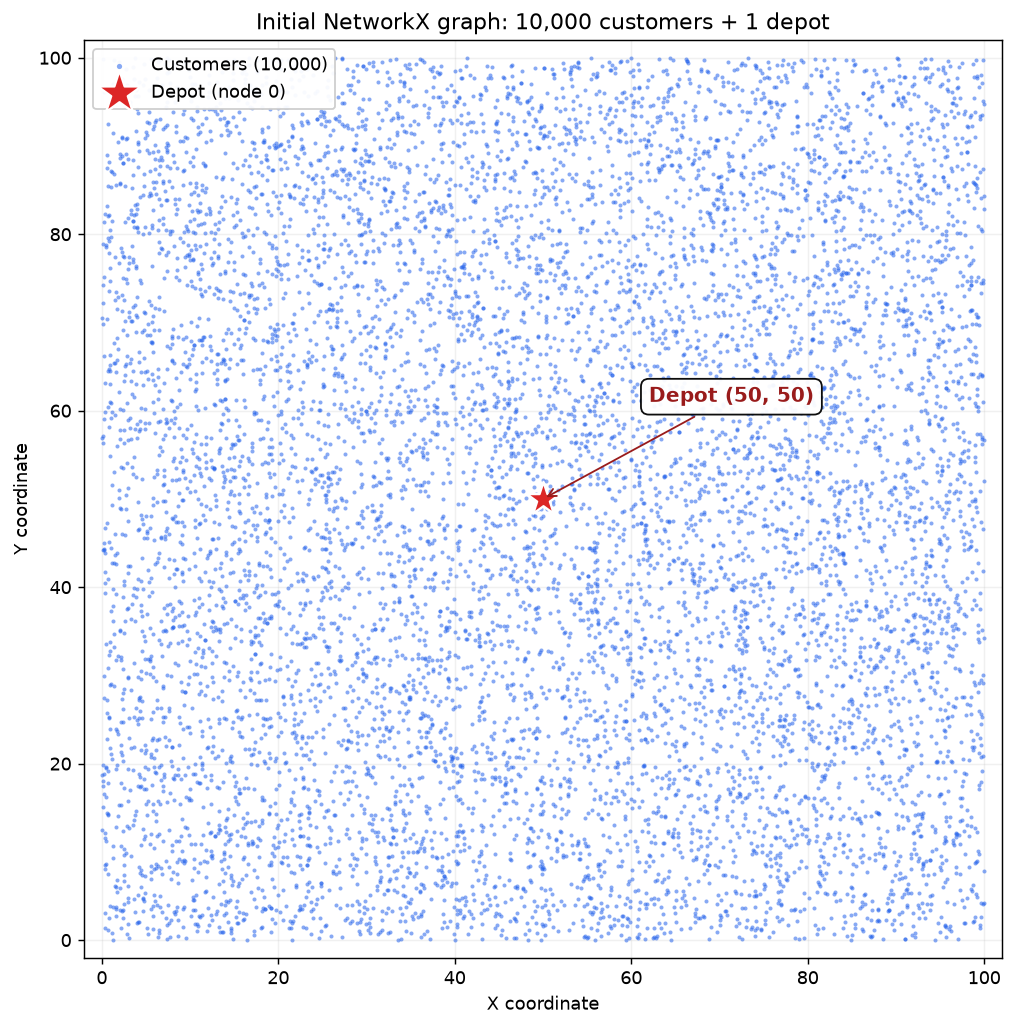

In [15]:
# Initial spatial graph: all customers and the depot, before route construction.
import matplotlib.pyplot as plt

synthetic_large_graph, synthetic_large_instance = synthetic_instance(10000, 'uniform', 100.0, 101)
synthetic_layout_positions = nx.get_node_attributes(synthetic_large_graph, 'pos')
synthetic_layout_fig, synthetic_layout_ax = plt.subplots(figsize=(9, 8))
synthetic_customer_points = nx.draw_networkx_nodes(
    synthetic_large_graph, synthetic_layout_positions,
    nodelist=list(range(1, synthetic_large_instance.n_customers + 1)),
    node_size=5, node_color='#2563eb', alpha=0.55, linewidths=0,
    label='Customers (10,000)', ax=synthetic_layout_ax)
synthetic_customer_points.set_rasterized(True)
synthetic_depot_xy = synthetic_large_instance.coords[0]
synthetic_layout_ax.scatter(*synthetic_depot_xy, marker='*', s=380, color='#dc2626',
                            edgecolor='white', linewidth=1.3, zorder=5,
                            label='Depot (node 0)')
synthetic_layout_ax.annotate('Depot (50, 50)', xy=synthetic_depot_xy, xytext=(62, 61),
                            fontsize=11, fontweight='bold', color='#991b1b',
                            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.95),
                            arrowprops=dict(arrowstyle='->', color='#991b1b'), zorder=6)
synthetic_layout_ax.set(title='Initial NetworkX graph: 10,000 customers + 1 depot',
                        xlabel='X coordinate', ylabel='Y coordinate',
                        xlim=(-2, 102), ylim=(-2, 102))
synthetic_layout_ax.set_aspect('equal')
synthetic_layout_ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
synthetic_layout_ax.grid(alpha=0.18)
synthetic_layout_ax.legend(loc='upper left', framealpha=0.95, markerscale=1.3)
synthetic_layout_fig.tight_layout()
plt.show()
del synthetic_large_graph  # Keep the instance for the shared SA run below.


### 11.1 Shared SA solver on 10,000 customers, without a time limit

This section calls the same public `sa()` solver as the earlier sections, using `SAParams(time_limit=None, iterations=10_000_000)`. It reuses the shared move kernel, Metropolis acceptance, feasibility checks and best-solution tracking. The same exponential temperature interpolation now follows proposed move count instead of elapsed time: T = T0 * (Tf / T0)^progress. With no deadline, progress is the fraction of the 10 million move attempts completed; the last batch reaches Tf = 0.02. Rejected and infeasible proposals count as attempts. The run stops after completing this finite cooling schedule, without claiming optimality.

A feasible sweep solution initializes the run through the public `initial` argument. Graph generation and sweep construction occur before the solver timer. Existing callers with a numeric `time_limit` retain their timed behavior and defaults; saved outputs in sections 1-10 are preserved. Untimed runs also bound route-array padding by positive customer demands and capacity, reducing memory copies while keeping all feasible moves available.


In [16]:
# Same public SA entry point and parameters as the other notebook sections.
synthetic_large_initial = synthetic_sweep(synthetic_large_instance)
synthetic_large_params = SAParams(time_limit=TIME_LIMIT, iterations=ITERATIONS)
synthetic_large_run = sa(synthetic_large_instance, synthetic_large_params, seed=TEST_SEEDS[0],
                         initial=synthetic_large_initial)
assert synthetic_large_run.best is not None
assert synthetic_large_run.best.is_feasible(synthetic_large_instance)
synthetic_large_solution = synthetic_large_run.best
synthetic_large_initial_cost = synthetic_large_initial.cost(synthetic_large_instance)
synthetic_large_history = pd.DataFrame(synthetic_large_run.history).rename(columns={'best': 'cost', 'iteration': 'iterations'})
synthetic_large_result = pd.DataFrame([dict(
    customers=10000, layout='uniform', capacity=100.0, graph_seed=101, solver_seed=TEST_SEEDS[0],
    time_limit=synthetic_large_params.time_limit,
    scheduled_moves=synthetic_large_params.iterations,
    initial_temperature_factor=synthetic_large_params.initial_temperature_factor,
    final_temperature=synthetic_large_params.final_temperature,
    initial_cost=synthetic_large_initial_cost, cost=synthetic_large_run.cost,
    improvement_pct=100*(synthetic_large_initial_cost-synthetic_large_run.cost)/synthetic_large_initial_cost,
    routes=len(synthetic_large_solution.routes), iterations=synthetic_large_run.iterations,
    accepted=synthetic_large_run.accepted, seconds=synthetic_large_run.runtime,
    feasible=synthetic_large_solution.is_feasible(synthetic_large_instance),
    stop_reason=synthetic_large_run.stop_reason)])
print(synthetic_large_result.to_string(index=False))


 customers  layout  capacity  graph_seed  solver_seed time_limit  scheduled_moves  initial_temperature_factor  final_temperature  initial_cost       cost  improvement_pct  routes  iterations  accepted  seconds  feasible stop_reason
     10000 uniform   100.000         101            1       None         10000000                       0.005              0.020    189072.076 119173.682           36.969     672    10000000   3357319   58.300      True  iterations


### 11.2 Graphs of the shared, untimed SA run

Convergence uses the shared solver's measured best-improvement history. The temperature plot shows the configured exponential schedule against proposed move count. Improvement over elapsed time, route loads and both maps refer to the same execution above. Elapsed seconds are measured, not a stopping criterion. Both maps include all customers and routes, with repeated colors and transparent lines to limit clutter. These are single-run diagnostics, not averages over multiple seeds.


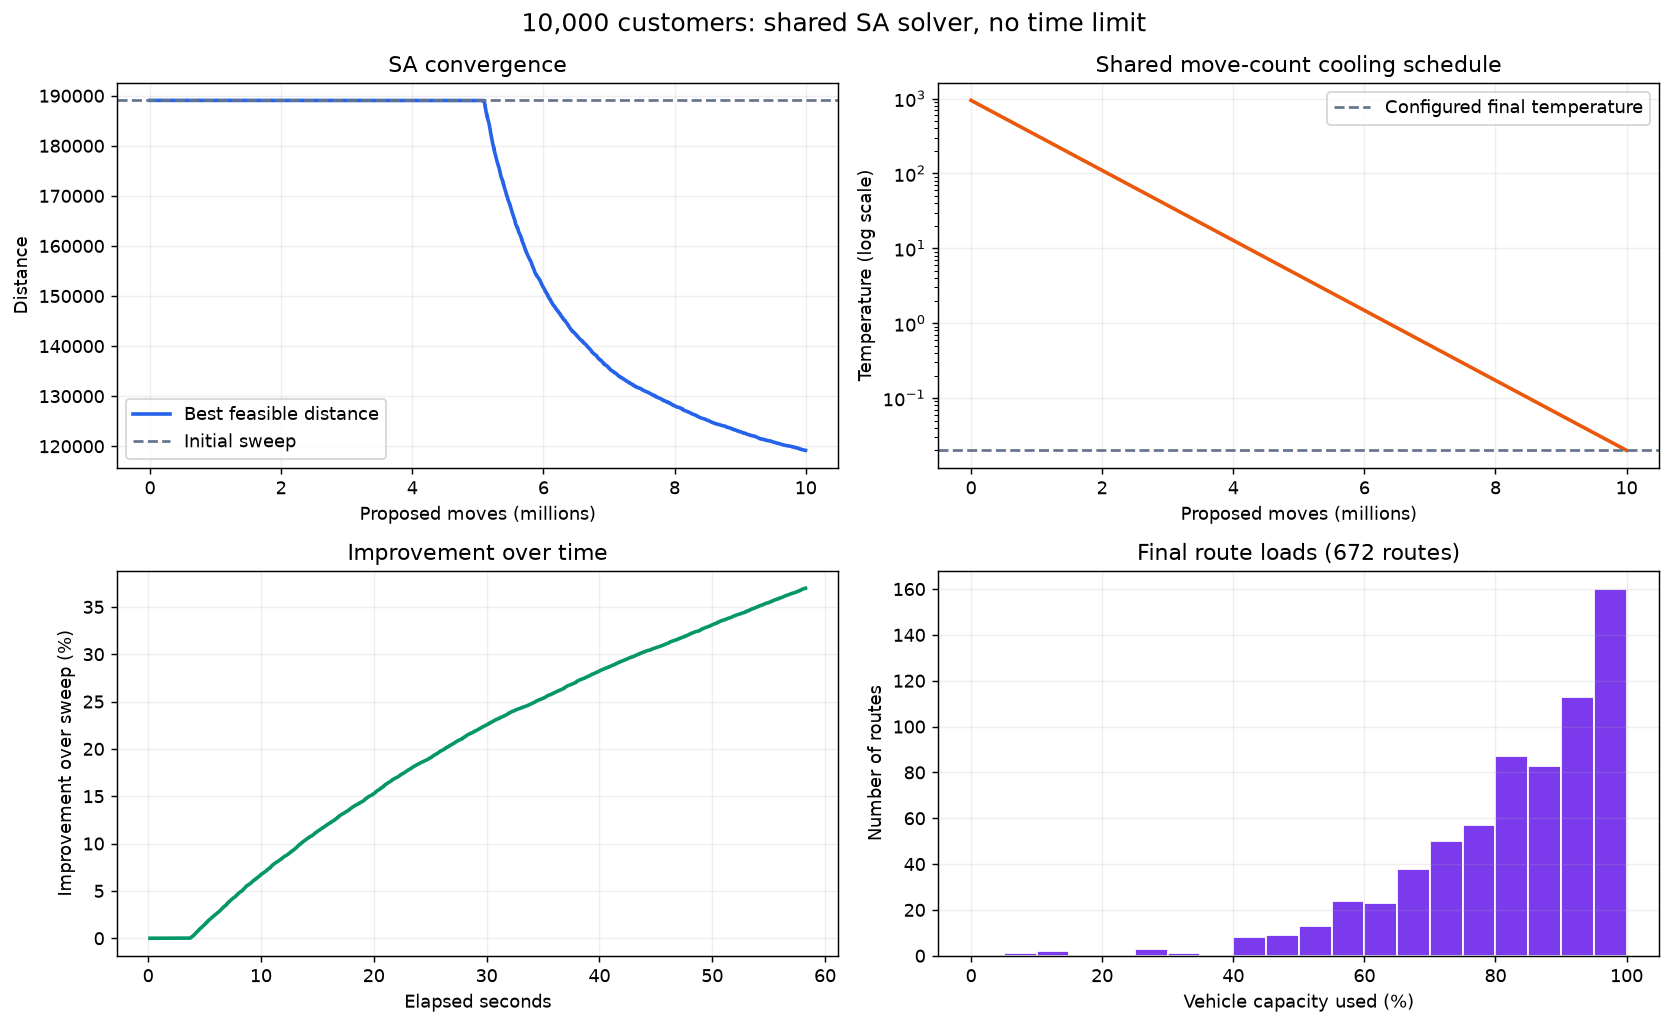

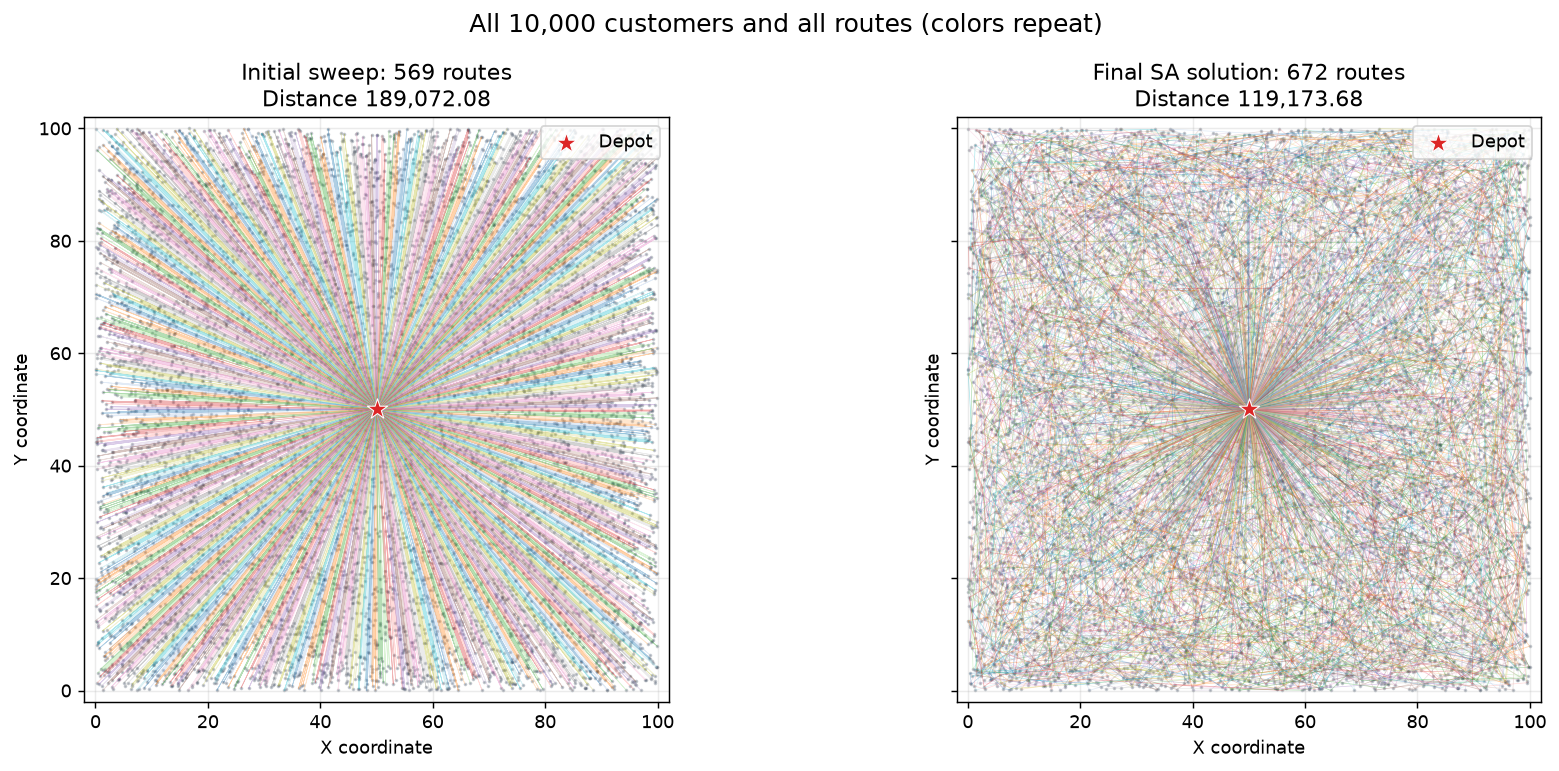

In [17]:
# Graphs use the shared SA result and measured improvement history above.
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

synthetic_plot_history = synthetic_large_history.copy()
synthetic_schedule_moves = np.linspace(0, synthetic_large_params.iterations, 300)
synthetic_schedule_t0 = max(1.0, synthetic_large_result.initial_cost.iloc[0]
                            * synthetic_large_params.initial_temperature_factor)
synthetic_schedule_temperature = synthetic_schedule_t0 * (
    synthetic_large_params.final_temperature / synthetic_schedule_t0
) ** (synthetic_schedule_moves / synthetic_large_params.iterations)
synthetic_plot_initial_cost = synthetic_large_result.initial_cost.iloc[0]
synthetic_plot_improvement = 100 * (1 - synthetic_plot_history.cost / synthetic_plot_initial_cost)
synthetic_plot_millions = synthetic_plot_history.iterations / 1e6

synthetic_diagnostics, synthetic_diagnostic_axes = plt.subplots(2, 2, figsize=(13, 8))
synthetic_diagnostic_axes[0, 0].plot(synthetic_plot_millions, synthetic_plot_history.cost,
                                   color='#2563eb', linewidth=2, label='Best feasible distance')
synthetic_diagnostic_axes[0, 0].axhline(synthetic_plot_initial_cost, color='#64748b',
                                      linestyle='--', label='Initial sweep')
synthetic_diagnostic_axes[0, 0].set(xlabel='Proposed moves (millions)', ylabel='Distance',
                                  title='SA convergence')
synthetic_diagnostic_axes[0, 0].legend()
synthetic_diagnostic_axes[0, 1].plot(synthetic_schedule_moves / 1e6, synthetic_schedule_temperature,
                                   color='#ea580c', linewidth=2)
synthetic_diagnostic_axes[0, 1].axhline(synthetic_large_params.final_temperature, color='#64748b',
                                      linestyle='--', label='Configured final temperature')
synthetic_diagnostic_axes[0, 1].set(yscale='log', xlabel='Proposed moves (millions)',
                                  ylabel='Temperature (log scale)', title='Shared move-count cooling schedule')
synthetic_diagnostic_axes[0, 1].legend()
synthetic_diagnostic_axes[1, 0].plot(synthetic_plot_history.seconds, synthetic_plot_improvement,
                                   color='#059669', linewidth=2)
synthetic_diagnostic_axes[1, 0].set(xlabel='Elapsed seconds',
                                  ylabel='Improvement over sweep (%)', title='Improvement over time')
synthetic_plot_loads = np.array([
    synthetic_large_instance.demands[route].sum()
    for route in synthetic_large_solution.routes])
synthetic_diagnostic_axes[1, 1].hist(synthetic_plot_loads / synthetic_large_instance.capacity * 100,
                                   bins=np.linspace(0, 100, 21), color='#7c3aed', edgecolor='white')
synthetic_diagnostic_axes[1, 1].set(xlabel='Vehicle capacity used (%)', ylabel='Number of routes',
                                  title=f'Final route loads ({len(synthetic_plot_loads)} routes)')
for synthetic_plot_ax in synthetic_diagnostic_axes.flat:
    synthetic_plot_ax.grid(alpha=0.2)
synthetic_diagnostics.suptitle('10,000 customers: shared SA solver, no time limit', fontsize=14)
synthetic_diagnostics.tight_layout()
plt.show()

# LineCollection draws every route without 10,000 separate point markers or a huge legend.
synthetic_maps, synthetic_map_axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
synthetic_plot_xy = synthetic_large_instance.coords
for synthetic_map_ax, synthetic_map_solution, synthetic_map_title in zip(
        synthetic_map_axes,
        (synthetic_large_initial, synthetic_large_solution),
        ('Initial sweep', 'Final SA solution')):
    synthetic_paths = [synthetic_plot_xy[[0, *route, 0]] for route in synthetic_map_solution.routes]
    synthetic_colors = plt.get_cmap('tab20')(np.arange(len(synthetic_paths)) % 20)
    synthetic_map_ax.add_collection(LineCollection(synthetic_paths, colors=synthetic_colors,
                                                   linewidths=0.4, alpha=0.35))
    synthetic_map_ax.scatter(synthetic_plot_xy[1:, 0], synthetic_plot_xy[1:, 1],
                             s=1, color='#334155', alpha=0.25, rasterized=True)
    synthetic_map_ax.scatter(*synthetic_plot_xy[0], marker='*', s=140, color='#dc2626',
                             edgecolor='white', linewidth=0.6, zorder=5, label='Depot')
    synthetic_map_ax.set(xlim=(-2, 102), ylim=(-2, 102), xlabel='X coordinate', ylabel='Y coordinate',
                         title=f'{synthetic_map_title}: {len(synthetic_map_solution.routes)} routes'
                               f'\nDistance {synthetic_map_solution.cost(synthetic_large_instance):,.2f}')
    synthetic_map_ax.set_aspect('equal')
    synthetic_map_ax.legend(loc='upper right')
synthetic_maps.suptitle('All 10,000 customers and all routes (colors repeat)', fontsize=14)
synthetic_maps.tight_layout()
plt.show()
